# Problem 2: Binary-Latent Autoencoder (MNIST)

Compresses each 28×28 image into a 3×4×4 grid of ±1 values (48 bits) and reconstructs it. Target: mean PSNR > 25 dB on the **1024-image** training subset.

**Before running:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all.

In [1]:
import copy
import random

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

## Setup

In [2]:
SEED = 42
DATA_DIR = "./data"
NUM_TRAIN = 1024
EPOCHS = 300
WARMUP_EPOCHS = 30        # train with continuous latent first, then switch to binary
LR = 5e-4
NOISE_STD = 0.2           # Gaussian noise on latent, fades linearly to 0 during binary training
FINETUNE_EPOCHS = 150     # final stage: encoder frozen, decoder only
FINETUNE_LR = 2e-4
TARGET_PSNR = 25.0

random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Data

In [3]:
transform = transforms.ToTensor()
full_train = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)
test_data = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)

subset_idx = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(SEED))[:NUM_TRAIN]
train_data = Subset(full_train, subset_idx.tolist())

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
train_eval_loader = DataLoader(train_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=256, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 340kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.17MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.1MB/s]


## Model

In [4]:
def binary_ste(x):
    """Forward: sign(x) in {-1, +1}. Backward: identity (straight-through)."""
    hard = torch.where(x >= 0, torch.ones_like(x), -torch.ones_like(x))
    return x + (hard - x).detach()


def conv_block(c_in, c_out, k=3, stride=1, padding=1):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, k, stride=stride, padding=padding),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
    )


class BinaryAutoencoder(nn.Module):
    def __init__(self, noise_std=NOISE_STD):
        super().__init__()
        self.noise_std = noise_std
        self.binarize = False     # switched on after warm-up

        # 1x28x28 -> 3x4x4
        self.encoder = nn.Sequential(
            conv_block(1, 64),
            conv_block(64, 128, 4, stride=2),     # 28 -> 14
            conv_block(128, 256, 4, stride=2),    # 14 -> 7
            conv_block(256, 256, 3, stride=2),    # 7 -> 4
            nn.Conv2d(256, 3, kernel_size=1),     # 3 latent channels
            nn.BatchNorm2d(3, affine=False),      # keeps tanh out of saturation, balances bits
        )

        # 3x4x4 -> 1x28x28 (raw output, clamped to [0, 1] for PSNR)
        self.decoder = nn.Sequential(
            conv_block(3, 256),
            nn.Upsample(size=(7, 7), mode="bilinear", align_corners=False),
            conv_block(256, 256),
            nn.Upsample(size=(14, 14), mode="bilinear", align_corners=False),
            conv_block(256, 128),
            nn.Upsample(size=(28, 28), mode="bilinear", align_corners=False),
            conv_block(128, 64),
            nn.Conv2d(64, 1, 3, padding=1),
        )

    def encode(self, x):
        latent = torch.tanh(self.encoder(x))                          # soft values in [-1, 1]
        if not self.binarize:
            return latent                                             # warm-up: continuous
        if self.training:
            latent = latent + torch.randn_like(latent) * self.noise_std
        return binary_ste(latent)                                     # hard -1 / +1

    def forward(self, x):
        z = self.encode(x)
        return self.decoder(z), z

## Evaluation

In [5]:
def mean_psnr(model, loader):
    model.eval()
    values = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            recon, _ = model(images)
            mse = (images - recon.clamp(0, 1)).square().mean(dim=(1, 2, 3))
            values.append(10 * torch.log10(1.0 / mse.clamp_min(1e-10)))
    return torch.cat(values).mean().item()

## Training

In [6]:
model = BinaryAutoencoder().to(device)
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)
criterion = nn.MSELoss()

best_psnr = float("-inf")
best_state = copy.deepcopy(model.state_dict())
losses = []

def train_one_epoch(optimizer, freeze_encoder=False):
    model.train()
    if freeze_encoder:
        model.encoder.eval()                      # freeze BatchNorm stats -> fixed codes
    running = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        optimizer.zero_grad()
        recon, _ = model(images)
        loss = criterion(recon, images)
        loss.backward()
        optimizer.step()
        running += loss.item()
    return running / len(train_loader)


def check(epoch, stage):
    global best_psnr, best_state
    psnr = mean_psnr(model, train_eval_loader)
    if model.binarize and psnr > best_psnr:       # only keep truly binary models
        best_psnr = psnr
        best_state = copy.deepcopy(model.state_dict())
    print(f"[{stage}] Epoch {epoch:3d} | loss {losses[-1]:.6f} | noise {model.noise_std:.3f} "
          f"| train PSNR {psnr:.2f} dB", flush=True)


# Stage 1: warm-up (continuous latent) + binary training with noise fading to 0
print(f"Device: {device} | train images: {len(train_data)} | epochs: {EPOCHS} + {FINETUNE_EPOCHS}")
for epoch in range(1, EPOCHS + 1):
    if epoch == WARMUP_EPOCHS + 1:
        model.binarize = True
        print("--- switching to binary latent ---", flush=True)
    if model.binarize:
        progress = (epoch - WARMUP_EPOCHS) / (EPOCHS - WARMUP_EPOCHS)
        model.noise_std = NOISE_STD * max(0.0, 1.0 - progress)
    losses.append(train_one_epoch(optimizer))
    scheduler.step()
    if epoch % 10 == 0 or epoch == 1:
        check(epoch, "main")

# Stage 2: freeze encoder (fixed 48-bit codes), fine-tune decoder only
print("--- freezing encoder, fine-tuning decoder ---", flush=True)
model.load_state_dict(best_state)
model.noise_std = 0.0
for p in model.encoder.parameters():
    p.requires_grad = False
ft_optimizer = optim.Adam(model.decoder.parameters(), lr=FINETUNE_LR)
ft_scheduler = optim.lr_scheduler.CosineAnnealingLR(ft_optimizer, T_max=FINETUNE_EPOCHS, eta_min=1e-6)
for epoch in range(1, FINETUNE_EPOCHS + 1):
    losses.append(train_one_epoch(ft_optimizer, freeze_encoder=True))
    ft_scheduler.step()
    if epoch % 10 == 0:
        check(epoch, "decoder")

Device: cuda | train images: 1024 | epochs: 300 + 150
[main] Epoch   1 | loss 0.080296 | noise 0.200 | train PSNR 11.05 dB
[main] Epoch  10 | loss 0.013969 | noise 0.200 | train PSNR 19.49 dB
[main] Epoch  20 | loss 0.009301 | noise 0.200 | train PSNR 21.62 dB
[main] Epoch  30 | loss 0.007897 | noise 0.200 | train PSNR 22.01 dB
--- switching to binary latent ---
[main] Epoch  40 | loss 0.025056 | noise 0.193 | train PSNR 16.79 dB
[main] Epoch  50 | loss 0.022170 | noise 0.185 | train PSNR 17.51 dB
[main] Epoch  60 | loss 0.020414 | noise 0.178 | train PSNR 17.95 dB
[main] Epoch  70 | loss 0.019298 | noise 0.170 | train PSNR 18.09 dB
[main] Epoch  80 | loss 0.017599 | noise 0.163 | train PSNR 18.51 dB
[main] Epoch  90 | loss 0.016348 | noise 0.156 | train PSNR 18.91 dB
[main] Epoch 100 | loss 0.016019 | noise 0.148 | train PSNR 19.08 dB
[main] Epoch 110 | loss 0.014764 | noise 0.141 | train PSNR 19.44 dB
[main] Epoch 120 | loss 0.013752 | noise 0.133 | train PSNR 19.65 dB
[main] Epoch 1

## Results


Latent shape:        (3, 4, 4)
Unique latent values: [-1.0, 1.0]
Train PSNR (1024 imgs): 29.96 dB
Test PSNR (10k imgs):  16.75 dB
Target > 25.0 dB:    MET
Saved model, loss curve and reconstruction figure.


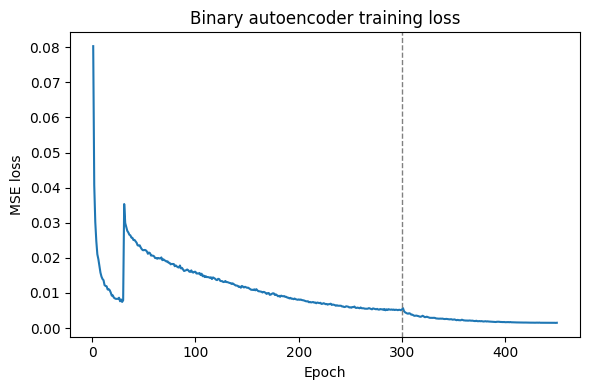

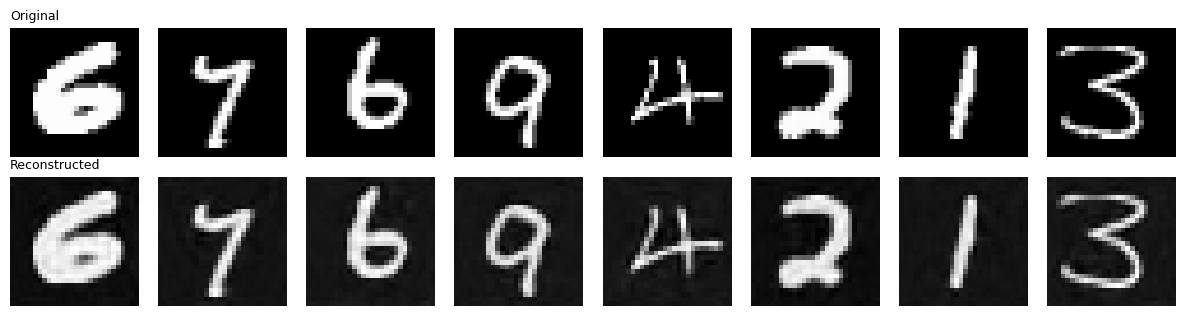

In [7]:
model.load_state_dict(best_state)
train_psnr = mean_psnr(model, train_eval_loader)
test_psnr = mean_psnr(model, test_loader)

model.eval()
images, _ = next(iter(train_eval_loader))
images = images.to(device)
with torch.no_grad():
    recon, z = model(images)

print(f"\nLatent shape:        {tuple(z.shape[1:])}")
print(f"Unique latent values: {torch.unique(z).tolist()}")
print(f"Train PSNR ({NUM_TRAIN} imgs): {train_psnr:.2f} dB")
print(f"Test PSNR (10k imgs):  {test_psnr:.2f} dB")
print(f"Target > {TARGET_PSNR} dB:    {'MET' if train_psnr > TARGET_PSNR else 'NOT MET'}")

torch.save(model.state_dict(), "binary_autoencoder.pt")

# Loss curve
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(losses) + 1), losses)
plt.axvline(EPOCHS, color="gray", linestyle="--", linewidth=1)   # start of decoder fine-tune
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Binary autoencoder training loss")
plt.tight_layout()
plt.savefig("binary_ae_loss.png", dpi=120)

# Originals (top) vs reconstructions (bottom)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i in range(8):
    axes[0, i].imshow(images[i, 0].cpu(), cmap="gray")
    axes[1, i].imshow(recon[i, 0].cpu(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_title("Original", loc="left", fontsize=9)
axes[1, 0].set_title("Reconstructed", loc="left", fontsize=9)
plt.tight_layout()
plt.savefig("binary_ae_reconstructions.png", dpi=120)
print("Saved model, loss curve and reconstruction figure.")

plt.show()

## Download results
Downloads the model and figures to your computer (Colab deletes files when the session ends).

In [8]:
from google.colab import files

for name in ["binary_autoencoder.pt", "binary_ae_loss.png", "binary_ae_reconstructions.png"]:
    files.download(name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>